# Análisis estadístico — Online Retail II

## Continuación del proyecto Online Retail

Este proyecto constituye la fase estadística del análisis realizado previamente sobre el dataset **Online Retail II**.

En la fase de **Python** se realizó la carga, limpieza, transformación, creación de variables y análisis exploratorio de los datos. El dataset procesado resultante (`onlineRetail_clean.csv`) se utiliza como punto de partida para este nuevo análisis.

El objetivo de esta fase es aplicar técnicas de **estadística descriptiva y econometría** para estudiar los factores asociados al valor económico de los pedidos.

### Pregunta de investigación

**¿Qué características de un pedido están asociadas con un mayor importe de compra?**

Para responderla se analizarán:

- estadísticos descriptivos;
- distribuciones y valores atípicos;
- relaciones y correlaciones entre variables;
- regresión lineal múltiple;
- diagnóstico del modelo;
- interpretación económica de los resultados.


In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/onlineRetail_clean.csv")

df = pd.read_csv(DATA_PATH)

print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

df.head()

Filas: 535186
Columnas: 15


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount,IsCancelled,Year,Month,MonthName,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,False,2010,12,December,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,2010,12,December,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,False,2010,12,December,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,2010,12,December,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,2010,12,December,Wednesday,8


## 1. Preparación de la muestra estadística

El dataset procesado en la fase de Python contiene una fila por cada línea de producto incluida en una factura.

Para el análisis estadístico se utilizará el **pedido (Invoice) como unidad de observación**, ya que el objetivo es estudiar qué características de un pedido están asociadas con su valor económico.

Se excluyen las líneas correspondientes a cancelaciones y se consideran únicamente ventas con cantidad y precio positivos. Posteriormente, las líneas de producto se agregan a nivel de factura.

In [2]:
sales = df[
    (~df["IsCancelled"]) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

print(f"Líneas totales del dataset: {len(df):,}")
print(f"Líneas de ventas válidas: {len(sales):,}")

Líneas totales del dataset: 535,186
Líneas de ventas válidas: 524,879


### Agregación a nivel de pedido

Las líneas de venta se agrupan por número de factura (`Invoice`). Para cada pedido se calculan:

- **OrderAmount**: importe económico total del pedido.
- **TotalUnits**: número total de unidades adquiridas.
- **UniqueProducts**: número de productos diferentes incluidos.
- **Country**: país asociado al pedido.
- **CustomerID**: identificador del cliente, cuando está disponible.
- **InvoiceDate**: fecha y hora del pedido.

De esta forma, cada fila del nuevo dataset representa un pedido completo y constituye una observación para el análisis estadístico.

In [3]:
orders = (
    sales
    .groupby("Invoice", as_index=False)
    .agg(
        OrderAmount=("TotalAmount", "sum"),
        TotalUnits=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        Country=("Country", "first"),
        CustomerID=("Customer ID", "first"),
        InvoiceDate=("InvoiceDate", "first")
    )
)

print(f"Número de pedidos: {len(orders):,}")

orders.head()

Número de pedidos: 19,960


,Invoice,OrderAmount,TotalUnits,UniqueProducts,Country,CustomerID,InvoiceDate
0,536365,139.12,40,7,United Kingdom,17850.0,2010-12-01 08:26:00
1,536366,22.20,12,2,United Kingdom,17850.0,2010-12-01 08:28:00
2,536367,278.73,83,12,United Kingdom,13047.0,2010-12-01 08:34:00
3,536368,70.05,15,4,United Kingdom,13047.0,2010-12-01 08:34:00
4,536369,17.85,3,1,United Kingdom,13047.0,2010-12-01 08:35:00


### Validación de la agregación

Antes de iniciar el análisis estadístico se comprueba que las variables asociadas al pedido sean consistentes dentro de cada factura.

En particular, se verifica que una misma factura no presente múltiples países, clientes o fechas de compra.

In [4]:
validation = sales.groupby("Invoice").agg(
    Countries=("Country", "nunique"),
    Customers=("Customer ID", "nunique"),
    Dates=("InvoiceDate", "nunique")
)

print("Facturas con más de un país:")
print((validation["Countries"] > 1).sum())

print("\nFacturas con más de un cliente:")
print((validation["Customers"] > 1).sum())

print("\nFacturas con más de una fecha:")
print((validation["Dates"] > 1).sum())

Facturas con más de un país:
0

Facturas con más de un cliente:
0

Facturas con más de una fecha:
42


In [5]:
invoices_multiple_dates = validation[
    validation["Dates"] > 1
].index

print(f"Facturas afectadas: {len(invoices_multiple_dates)}")

sales[
    sales["Invoice"].isin(invoices_multiple_dates)
][
    ["Invoice", "InvoiceDate", "StockCode", "Quantity", "Price"]
].sort_values(
    ["Invoice", "InvoiceDate"]
).head(30)

Facturas afectadas: 42


,Invoice,InvoiceDate,StockCode,Quantity,Price
2367,536591,2010-12-01 16:57:00,21427,1,2.10
2368,536591,2010-12-01 16:57:00,22135,1,0.42
2369,536591,2010-12-01 16:57:00,90214M,1,1.25
2370,536591,2010-12-01 16:57:00,90214V,1,1.25
2371,536591,2010-12-01 16:57:00,90214S,1,1.25
2372,536591,2010-12-01 16:57:00,90214J,2,1.25
2373,536591,2010-12-01 16:57:00,22386,1,1.95
2374,536591,2010-12-01 16:57:00,22378,1,2.10
2375,536591,2010-12-01 16:57:00,20750,1,7.95
2376,536591,2010-12-01 16:57:00,21888,1,3.75


In [6]:
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

In [7]:
date_ranges = (
    sales[
        sales["Invoice"].isin(invoices_multiple_dates)
    ]
    .groupby("Invoice")["InvoiceDate"]
    .agg(["min", "max", "nunique"])
)

date_ranges["Difference"] = (
    date_ranges["max"] - date_ranges["min"]
)

date_ranges.sort_values(
    "Difference",
    ascending=False
).head(10)

,min,max,nunique,Difference
Invoice,,,,
536591,2010-12-01 16:57:00,2010-12-01 16:58:00,2,0 days 00:01:00
553556,2011-05-17 16:48:00,2011-05-17 16:49:00,2,0 days 00:01:00
549524,2011-04-08 15:41:00,2011-04-08 15:42:00,2,0 days 00:01:00
550320,2011-04-17 12:37:00,2011-04-17 12:38:00,2,0 days 00:01:00
550333,2011-04-17 14:05:00,2011-04-17 14:06:00,2,0 days 00:01:00
550641,2011-04-19 15:53:00,2011-04-19 15:54:00,2,0 days 00:01:00
550645,2011-04-19 16:30:00,2011-04-19 16:31:00,2,0 days 00:01:00
552000,2011-05-05 15:55:00,2011-05-05 15:56:00,2,0 days 00:01:00
553199,2011-05-15 15:13:00,2011-05-15 15:14:00,2,0 days 00:01:00


In [8]:
orders = (
    sales
    .groupby("Invoice", as_index=False)
    .agg(
        OrderAmount=("TotalAmount", "sum"),
        TotalUnits=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        Country=("Country", "first"),
        CustomerID=("Customer ID", "first"),
        InvoiceDate=("InvoiceDate", "min")
    )
)

print(f"Número de pedidos: {len(orders):,}")

orders.head()

Número de pedidos: 19,960


,Invoice,OrderAmount,TotalUnits,UniqueProducts,Country,CustomerID,InvoiceDate
0,536365,139.12,40,7,United Kingdom,17850.0,2010-12-01 08:26:00
1,536366,22.20,12,2,United Kingdom,17850.0,2010-12-01 08:28:00
2,536367,278.73,83,12,United Kingdom,13047.0,2010-12-01 08:34:00
3,536368,70.05,15,4,United Kingdom,13047.0,2010-12-01 08:34:00
4,536369,17.85,3,1,United Kingdom,13047.0,2010-12-01 08:35:00


La validación mostró que cada factura está asociada a un único país y a un único cliente identificado.

En 42 facturas se observaron dos marcas temporales diferentes entre sus líneas. La diferencia máxima fue de un minuto, por lo que se interpretan como líneas pertenecientes al mismo proceso de compra. Para representar temporalmente cada pedido se utiliza la primera marca temporal registrada (`min`).

In [9]:
print("TIPOS DE DATOS")
print(orders.dtypes)

print("\nVALORES NULOS")
print(orders.isnull().sum())

print("\nESTADÍSTICOS DESCRIPTIVOS")
display(
    orders[
        ["OrderAmount", "TotalUnits", "UniqueProducts"]
    ].describe()
)

TIPOS DE DATOS
Invoice                      str
OrderAmount              float64
TotalUnits                 int64
UniqueProducts             int64
Country                      str
CustomerID               float64
InvoiceDate       datetime64[us]
dtype: object

VALORES NULOS
Invoice              0
OrderAmount          0
TotalUnits           0
UniqueProducts       0
Country              0
CustomerID        1428
InvoiceDate          0
dtype: int64

ESTADÍSTICOS DESCRIPTIVOS


,OrderAmount,TotalUnits,UniqueProducts
count,19960.000000,19960.000000,19960.000000
mean,533.172786,279.179409,26.032214
std,1780.412148,955.011800,46.982184
min,0.380000,1.000000,1.000000
25%,151.695000,69.000000,6.000000
50%,303.300000,150.000000,15.000000
75%,493.462500,296.000000,29.000000
max,168469.600000,80995.000000,1110.000000


### Interpretación inicial

El conjunto de datos estadístico contiene 19.960 pedidos. Las variables económicas y de volumen no presentan valores ausentes, mientras que 1.428 pedidos carecen de identificador de cliente. Dado que `CustomerID` funciona como identificador y no como variable cuantitativa explicativa, estos pedidos se mantienen inicialmente en el análisis.

Las variables `OrderAmount`, `TotalUnits` y `UniqueProducts` presentan medias superiores a sus respectivas medianas y valores máximos muy alejados del tercer cuartil. Estos resultados sugieren distribuciones asimétricas hacia la derecha y la presencia de observaciones extremas.

Antes de tomar decisiones sobre estos valores, se analizarán gráficamente sus distribuciones y posibles outliers.

In [10]:
import matplotlib.pyplot as plt

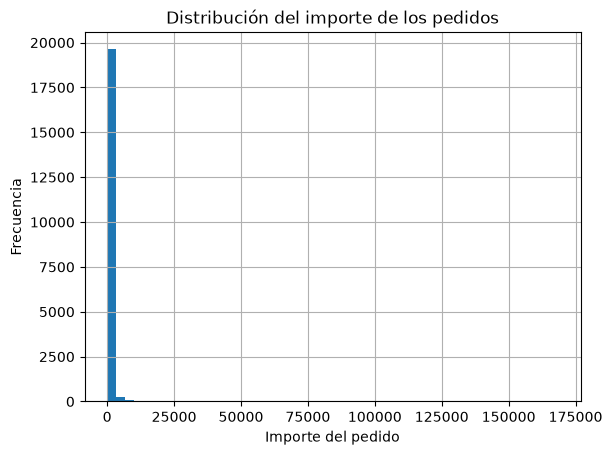

In [11]:
orders["OrderAmount"].hist(bins=50)

plt.title("Distribución del importe de los pedidos")
plt.xlabel("Importe del pedido")
plt.ylabel("Frecuencia")
plt.show()

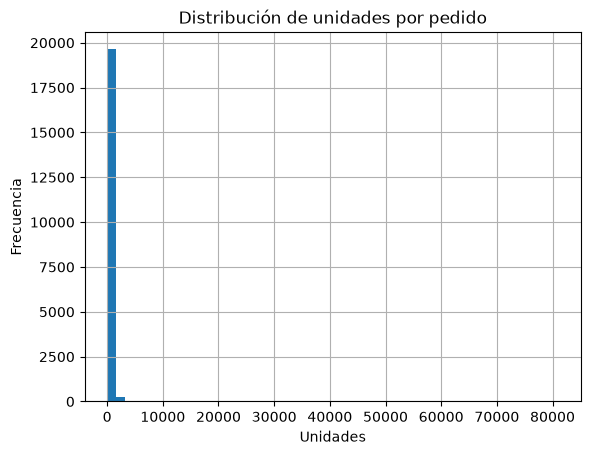

In [12]:
orders["TotalUnits"].hist(bins=50)

plt.title("Distribución de unidades por pedido")
plt.xlabel("Unidades")
plt.ylabel("Frecuencia")
plt.show()

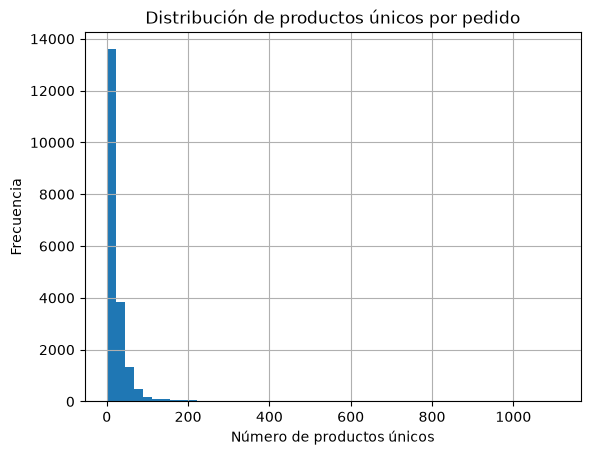

In [13]:
orders["UniqueProducts"].hist(bins=50)

plt.title("Distribución de productos únicos por pedido")
plt.xlabel("Número de productos únicos")
plt.ylabel("Frecuencia")
plt.show()

## 3. Distribuciones y valores atípicos

Los histogramas muestran una marcada asimetría positiva en las tres variables cuantitativas. La mayor parte de los pedidos se concentra en valores relativamente bajos, mientras que un número reducido de observaciones alcanza valores muy elevados.

Para cuantificar la presencia de valores atípicos se utiliza el criterio del rango intercuartílico (IQR). Una observación se considera potencialmente atípica cuando se encuentra por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

La identificación de un valor como atípico no implica su eliminación automática, ya que puede representar una operación comercial real.

In [14]:
variables = ["OrderAmount", "TotalUnits", "UniqueProducts"]

for variable in variables:
    q1 = orders[variable].quantile(0.25)
    q3 = orders[variable].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = orders[
        (orders[variable] < lower_limit) |
        (orders[variable] > upper_limit)
    ]

    print(f"\n{variable}")
    print(f"Límite inferior: {lower_limit:.2f}")
    print(f"Límite superior: {upper_limit:.2f}")
    print(f"Número de outliers: {len(outliers):,}")
    print(f"Porcentaje: {len(outliers) / len(orders) * 100:.2f}%")


OrderAmount
Límite inferior: -360.96
Límite superior: 1006.11
Número de outliers: 1,811
Porcentaje: 9.07%

TotalUnits
Límite inferior: -271.50
Límite superior: 636.50
Número de outliers: 1,445
Porcentaje: 7.24%

UniqueProducts
Límite inferior: -28.50
Límite superior: 63.50
Número de outliers: 1,385
Porcentaje: 6.94%


In [15]:
orders.sort_values(
    "OrderAmount",
    ascending=False
)[
    [
        "Invoice",
        "OrderAmount",
        "TotalUnits",
        "UniqueProducts",
        "Country",
        "CustomerID",
        "InvoiceDate"
    ]
].head(10)

,Invoice,OrderAmount,TotalUnits,UniqueProducts,Country,CustomerID,InvoiceDate
19923,581483,168469.60,80995,1,United Kingdom,16446.0,2011-12-09 09:15:00
2116,541431,77183.60,74215,1,United Kingdom,12346.0,2011-01-18 10:01:00
16923,574941,52940.94,14149,101,United Kingdom,NaN,2011-11-07 17:42:00
17579,576365,50653.91,13956,99,United Kingdom,NaN,2011-11-14 17:55:00
8693,556444,38970.00,60,1,United Kingdom,15098.0,2011-06-10 15:28:00
13545,567423,31698.16,12572,12,United Kingdom,17450.0,2011-09-20 11:05:00
8899,556917,22775.93,15049,138,Australia,12415.0,2011-06-15 13:37:00
15693,572209,22206.00,1920,7,United Kingdom,18102.0,2011-10-21 12:08:00
13537,567381,22104.80,6760,12,United Kingdom,17450.0,2011-09-20 10:12:00
11881,563614,21880.44,12196,97,Australia,12415.0,2011-08-18 08:51:00


### Inspección de los pedidos con mayor importe

La revisión de los pedidos con mayor `OrderAmount` identificó dos operaciones especialmente extremas: las facturas `581483` y `541431`, caracterizadas por un número excepcionalmente elevado de unidades de un único producto.

Para determinar si estas observaciones representan ventas efectivas o si corresponden a operaciones posteriormente anuladas, se examinan conjuntamente las facturas originales y sus respectivas facturas de cancelación.

La comparación permite comprobar si las cantidades vendidas fueron posteriormente revertidas mediante una operación de signo contrario.

In [16]:
df[
    df["Invoice"].isin(
        ["581483", "C581484", "541431", "C541433"]
    )
][
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "Price",
        "Customer ID",
        "InvoiceDate",
        "IsCancelled"
    ]
].sort_values("Invoice")

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate,IsCancelled
60845,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00,False
533704,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00,False
60850,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,2011-01-18 10:17:00,True
533705,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,2011-12-09 09:27:00,True


#### Resultado

Las dos operaciones extremas fueron posteriormente anuladas en su totalidad.

- La factura `541431`, correspondiente a 74.215 unidades, fue revertida mediante la factura de cancelación `C541433`.
- La factura `581483`, correspondiente a 80.995 unidades, fue revertida mediante la factura de cancelación `C581484`.

En ambos casos coinciden el producto, la cantidad en valor absoluto, el precio y el cliente. Por tanto, estas operaciones no representan ventas efectivas finales.

Este resultado indica que, para construir la muestra estadística definitiva, no basta con excluir las facturas de cancelación: también es necesario estudiar las ventas originales que fueron posteriormente revertidas.

## 4. Tratamiento de cancelaciones

El análisis de los valores extremos mostró que excluir únicamente las facturas identificadas como cancelaciones no garantiza que la muestra represente ventas efectivas, ya que la venta original permanece registrada como una operación positiva.

Por ello, se analizan las líneas de cancelación para identificar operaciones que revierten ventas anteriores. Este procedimiento permite diferenciar entre ventas efectivas y operaciones posteriormente anuladas, evitando eliminar automáticamente pedidos legítimos de gran volumen.

In [17]:
cancelled = df[
    (df["IsCancelled"]) &
    (df["Quantity"] < 0) &
    (df["Price"] > 0)
].copy()

print(f"Líneas de cancelación: {len(cancelled):,}")
print(f"Facturas de cancelación: {cancelled['Invoice'].nunique():,}")

cancelled[
    [
        "Invoice",
        "StockCode",
        "Quantity",
        "Price",
        "Customer ID",
        "InvoiceDate"
    ]
].head()

Líneas de cancelación: 9,251
Facturas de cancelación: 3,836


,Invoice,StockCode,Quantity,Price,Customer ID,InvoiceDate
141,C536379,D,-1,27.50,14527.0,2010-12-01 09:41:00
154,C536383,35004C,-1,4.65,15311.0,2010-12-01 09:49:00
235,C536391,22556,-12,1.65,17548.0,2010-12-01 10:24:00
236,C536391,21984,-24,0.29,17548.0,2010-12-01 10:24:00
237,C536391,21983,-24,0.29,17548.0,2010-12-01 10:24:00


### Correspondencia entre ventas y cancelaciones

Las cancelaciones se registran como nuevas líneas con cantidades negativas. Una cancelación puede afectar a la totalidad de una compra o únicamente a una parte de ella.

Por este motivo, no se eliminan directamente las facturas originales asociadas a cancelaciones. En primer lugar, se analiza la correspondencia entre las líneas positivas de venta y las líneas negativas posteriores utilizando información como el cliente, el producto, el precio y la cantidad.

In [18]:
print("Cancelaciones con Customer ID:")
print(cancelled["Customer ID"].notna().sum())

print("\nCancelaciones sin Customer ID:")
print(cancelled["Customer ID"].isna().sum())

print("\nProductos diferentes cancelados:")
print(cancelled["StockCode"].nunique())

print("\nRango de fechas:")
print(cancelled["InvoiceDate"].min())
print(cancelled["InvoiceDate"].max())

Cancelaciones con Customer ID:
8872

Cancelaciones sin Customer ID:
379

Productos diferentes cancelados:
1947

Rango de fechas:
2010-12-01 09:41:00
2011-12-09 11:58:00


### Preparación de ventas y cancelaciones

Para analizar la relación entre las ventas originales y sus posibles cancelaciones posteriores, se separan las operaciones en dos conjuntos de datos.

Por un lado, se seleccionan las líneas correspondientes a ventas positivas, excluyendo cancelaciones y operaciones con cantidades o precios no positivos. Por otro, se seleccionan las líneas de cancelación, caracterizadas por cantidades negativas.

La variable `InvoiceDate` se convierte a formato fecha y hora para poder comprobar posteriormente que una cancelación sea posterior a la venta que potencialmente revierte.

Finalmente, se crea `CancelledQuantity`, que representa la cantidad cancelada en valor absoluto. Esto facilita la comparación entre las unidades originalmente vendidas y las posteriormente canceladas sin perder la identificación de la operación como cancelación.

In [19]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

sales_lines = df[
    (~df["IsCancelled"]) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

cancelled_lines = df[
    (df["IsCancelled"]) &
    (df["Quantity"] < 0) &
    (df["Price"] > 0)
].copy()

cancelled_lines["CancelledQuantity"] = cancelled_lines["Quantity"].abs()

In [20]:
example_customer = 16446.0
example_product = "23843"

df[
    (df["Customer ID"] == example_customer) &
    (df["StockCode"] == example_product)
][
    [
        "Invoice",
        "StockCode",
        "Quantity",
        "Price",
        "InvoiceDate",
        "IsCancelled"
    ]
].sort_values("InvoiceDate")

,Invoice,StockCode,Quantity,Price,InvoiceDate,IsCancelled
533704,581483,23843,80995,2.08,2011-12-09 09:15:00,False
533705,C581484,23843,-80995,2.08,2011-12-09 09:27:00,True


### Identificación de ventas potencialmente asociadas a cancelaciones

La inspección individual confirma que una cancelación puede reproducir exactamente el producto, el precio y la cantidad de una venta anterior. Sin embargo, este criterio no puede aplicarse directamente a todo el conjunto de datos, ya que un mismo cliente puede adquirir el mismo producto al mismo precio en diferentes pedidos.

Para identificar posibles correspondencias de forma más rigurosa, se consideran como criterios iniciales:

- el mismo cliente;
- el mismo producto (`StockCode`);
- el mismo precio;
- una venta realizada antes de la cancelación.

El objetivo de este análisis no es eliminar automáticamente todas las ventas relacionadas con una devolución, sino determinar hasta qué punto las cancelaciones pueden vincularse con operaciones positivas previas.

In [21]:
cancelled_known = cancelled_lines[
    cancelled_lines["Customer ID"].notna()
].copy()

candidate_matches = cancelled_known.merge(
    sales_lines,
    on=["Customer ID", "StockCode", "Price"],
    how="left",
    suffixes=("_cancel", "_sale")
)

candidate_matches = candidate_matches[
    candidate_matches["InvoiceDate_sale"] <
    candidate_matches["InvoiceDate_cancel"]
].copy()

print(f"Cancelaciones con cliente identificado: {len(cancelled_known):,}")
print(
    "Cancelaciones con al menos una venta previa candidata:",
    candidate_matches["Invoice_cancel"].nunique()
)

candidate_matches[
    [
        "Invoice_cancel",
        "Invoice_sale",
        "StockCode",
        "Quantity_cancel",
        "Quantity_sale",
        "Price",
        "Customer ID",
        "InvoiceDate_sale",
        "InvoiceDate_cancel"
    ]
].head(10)

Cancelaciones con cliente identificado: 8,872
Cancelaciones con al menos una venta previa candidata: 3031


,Invoice_cancel,Invoice_sale,StockCode,Quantity_cancel,Quantity_sale,Price,Customer ID,InvoiceDate_sale,InvoiceDate_cancel
12,C536506,536488,22960,-6,8.0,4.25,17897.0,2010-12-01 12:31:00,2010-12-01 12:38:00
93,C536737,536537,22798,-2,8.0,2.95,15922.0,2010-12-01 13:51:00,2010-12-02 13:05:00
95,C536758,536395,21314,-1,8.0,2.10,13767.0,2010-12-01 10:47:00,2010-12-02 14:25:00
146,C536826,536397,35004B,-2,12.0,4.65,17924.0,2010-12-01 10:51:00,2010-12-02 17:30:00
149,C536826,536397,35004B,-3,12.0,4.65,17924.0,2010-12-01 10:51:00,2010-12-02 17:30:00
167,C536979,536557,84685,-1,1.0,3.75,17841.0,2010-12-01 14:41:00,2010-12-03 14:23:00
177,C537024,536617,20893,-36,108.0,2.10,13941.0,2010-12-02 10:17:00,2010-12-03 16:21:00
191,C537143,537140,20685,-1,1.0,7.95,12748.0,2010-12-05 12:53:00,2010-12-05 12:58:00
193,C537157,537144,35953,-24,24.0,1.25,15880.0,2010-12-05 13:00:00,2010-12-05 13:09:00
195,C537203,536591,37449,-1,1.0,9.95,14606.0,2010-12-01 16:57:00,2010-12-05 14:44:00


#### Resultado del emparejamiento preliminar

El análisis identifica ventas previas candidatas para un número elevado de facturas de cancelación con cliente conocido.

Las primeras correspondencias muestran que las cantidades canceladas no siempre coinciden con las cantidades originalmente adquiridas. Por ejemplo, pueden cancelarse 6 unidades de una venta previa de 8 unidades, lo que indica la existencia de devoluciones o cancelaciones parciales.

Por tanto, exigir igualdad exacta entre la cantidad vendida y la cantidad cancelada excluiría operaciones legítimamente relacionadas.

Además, una misma cancelación puede disponer de varias ventas previas candidatas cuando un cliente ha comprado repetidamente el mismo producto al mismo precio. Por ello, el emparejamiento preliminar no se utiliza todavía para modificar la muestra estadística.

In [22]:
cancelled_known = cancelled_lines[
    cancelled_lines["Customer ID"].notna()
].copy()

cancelled_known["CancelLineID"] = cancelled_known.index

candidate_matches = cancelled_known.merge(
    sales_lines,
    on=["Customer ID", "StockCode", "Price"],
    how="left",
    suffixes=("_cancel", "_sale")
)

candidate_matches = candidate_matches[
    candidate_matches["InvoiceDate_sale"] <
    candidate_matches["InvoiceDate_cancel"]
].copy()

matched_lines = candidate_matches["CancelLineID"].nunique()
total_lines = len(cancelled_known)

print(f"Líneas de cancelación con cliente: {total_lines:,}")
print(f"Líneas con al menos una venta previa candidata: {matched_lines:,}")
print(f"Líneas sin venta previa candidata: {total_lines - matched_lines:,}")
print(f"Porcentaje con candidato: {matched_lines / total_lines * 100:.2f}%")

Líneas de cancelación con cliente: 8,872
Líneas con al menos una venta previa candidata: 7,230
Líneas sin venta previa candidata: 1,642
Porcentaje con candidato: 81.49%


#### Cobertura del emparejamiento

De las 8.872 líneas de cancelación con cliente identificado, 7.230 (81,49 %) presentan al menos una venta previa compatible según cliente, producto, precio y secuencia temporal.

Las 1.642 líneas restantes (18,51 %) no presentan una correspondencia previa bajo estos criterios. Estas observaciones no se emparejan de forma forzada, ya que la ausencia de una venta candidata puede deberse, entre otros motivos, a operaciones realizadas antes del periodo cubierto por el dataset o a diferencias entre los registros de venta y cancelación.

La elevada proporción de correspondencias confirma que las cancelaciones contienen información relevante sobre ventas previamente registradas. Sin embargo, la existencia de devoluciones parciales y de múltiples ventas candidatas hace necesario evitar una eliminación automática de las facturas originales.

### Identificación de cancelaciones totales

Como comprobación adicional, se buscan cancelaciones cuya cantidad en valor absoluto coincida exactamente con la cantidad de una venta previa del mismo cliente, producto y precio.

Este análisis permite identificar operaciones potencialmente revertidas en su totalidad sin asumir que todas las devoluciones parciales deban provocar la eliminación del pedido original.

In [23]:
exact_matches = candidate_matches[
    candidate_matches["CancelledQuantity"] ==
    candidate_matches["Quantity_sale"]
].copy()

exact_matches["TimeDifference"] = (
    exact_matches["InvoiceDate_cancel"] -
    exact_matches["InvoiceDate_sale"]
)

print(
    "Líneas con al menos una coincidencia exacta:",
    exact_matches["CancelLineID"].nunique()
)

exact_matches.sort_values("TimeDifference")[
    [
        "Invoice_sale",
        "Invoice_cancel",
        "StockCode",
        "Quantity_sale",
        "CancelledQuantity",
        "Price",
        "Customer ID",
        "TimeDifference"
    ]
].head(20)

Líneas con al menos una coincidencia exacta: 2797


,Invoice_sale,Invoice_cancel,StockCode,Quantity_sale,CancelledQuantity,Price,Customer ID,TimeDifference
19162,575878,C575879,21519,12.0,12,0.42,13588.0,0 days 00:01:00
10100,558895,C558897,M,1.0,1,389.68,12619.0,0 days 00:01:00
8014,554207,C554210,85132C,1.0,1,1.95,14573.0,0 days 00:01:00
16994,570849,C570850,22910,40.0,40,2.55,15473.0,0 days 00:01:00
4923,546734,C546735,22930,96.0,96,2.10,16029.0,0 days 00:01:00
4921,546734,C546735,22932,96.0,96,2.10,16029.0,0 days 00:01:00
4919,546734,C546735,22933,144.0,144,2.10,16029.0,0 days 00:01:00
5236,547407,C547408,22423,1.0,1,12.75,15658.0,0 days 00:01:00
6534,550354,C550355,M,1.0,1,222.75,13811.0,0 days 00:01:00
5826,548913,C548914,M,1.0,1,1136.30,12669.0,0 days 00:01:00


#### Resultado de las coincidencias exactas

Se identifican 2.797 líneas de cancelación que presentan al menos una coincidencia exacta con una venta previa en términos de cliente, producto, precio y cantidad.

En numerosos casos, la cancelación se produce pocos minutos después de la venta original, lo que es compatible con anulaciones o correcciones inmediatas de operaciones.

Sin embargo, una coincidencia exacta a nivel de línea no implica necesariamente que el pedido completo haya sido cancelado. Una factura puede contener múltiples productos y únicamente una parte de sus líneas puede haber sido posteriormente revertida.

Dado que la unidad de observación del análisis estadístico es el pedido, resulta necesario distinguir entre cancelaciones parciales y pedidos completamente revertidos.

### Identificación de pedidos completamente revertidos

Para evitar atribuir una cancelación a una venta anterior incorrecta, se restringe el análisis a coincidencias exactas producidas dentro de las 24 horas posteriores a la venta.

A continuación, se compara el número de líneas de cada factura original con el número de líneas que presentan una cancelación exacta posterior. Esta aproximación permite identificar candidatos a pedidos completamente revertidos, diferenciándolos de las devoluciones parciales.

In [24]:
exact_24h = exact_matches[
    exact_matches["TimeDifference"] <= pd.Timedelta(hours=24)
].copy()

# Evitamos contar varias veces la misma línea de venta
exact_24h = exact_24h.drop_duplicates(
    subset=["Invoice_sale", "StockCode", "Quantity_sale", "Price"]
)

# Número de líneas originales por factura
original_lines = (
    sales_lines
    .groupby("Invoice")
    .size()
    .rename("OriginalLines")
)

# Número de líneas con cancelación exacta dentro de 24 h
cancelled_exact_lines = (
    exact_24h
    .groupby("Invoice_sale")
    .size()
    .rename("CancelledExactLines")
)

invoice_cancellation_check = (
    pd.concat(
        [original_lines, cancelled_exact_lines],
        axis=1
    )
    .fillna(0)
)

invoice_cancellation_check["FullyReversedCandidate"] = (
    invoice_cancellation_check["OriginalLines"] ==
    invoice_cancellation_check["CancelledExactLines"]
)

fully_reversed = invoice_cancellation_check[
    invoice_cancellation_check["FullyReversedCandidate"]
]

print(
    "Pedidos candidatos a cancelación completa en 24 h:",
    len(fully_reversed)
)

fully_reversed.head(20)

Pedidos candidatos a cancelación completa en 24 h: 81


,OriginalLines,CancelledExactLines,FullyReversedCandidate
537217,4,4.0,True
537410,1,1.0,True
538313,30,30.0,True
538534,1,1.0,True
539109,2,2.0,True
540275,21,21.0,True
540842,1,1.0,True
541431,1,1.0,True
542725,2,2.0,True
543372,2,2.0,True


#### Resultado de la identificación de pedidos revertidos

Aplicando el criterio definido se identifican 81 pedidos candidatos a haber sido completamente revertidos dentro de las 24 horas posteriores a su registro.

Estos pedidos representan aproximadamente el 0,41 % de los 19.960 pedidos inicialmente incluidos en la muestra. La identificación se basa en la coincidencia de todas las líneas de la factura con cancelaciones exactas posteriores, considerando cliente, producto, precio y cantidad.

Entre los casos identificados se encuentra la factura `541431`, previamente detectada como una de las observaciones más extremas del conjunto de datos.

La exclusión de estos pedidos, en caso de realizarse, no se justificaría por su condición de valores atípicos, sino porque existe evidencia de que fueron completamente revertidos y, por tanto, no representan ventas efectivas finales.

In [25]:
fully_reversed.loc[
    fully_reversed.index.isin(["541431", "581483"])
]

,OriginalLines,CancelledExactLines,FullyReversedCandidate
541431,1,1.0,True
581483,1,1.0,True


### Construcción de la muestra estadística definitiva

La comprobación de los casos extremos confirma que las facturas `541431` y `581483`, responsables de algunos de los valores más elevados de unidades e importe, se encuentran entre los pedidos identificados como completamente revertidos.

A partir del criterio establecido se excluyen de la muestra los 81 pedidos candidatos a cancelación completa dentro de las 24 horas posteriores a la venta.

Esta exclusión no se basa en el tamaño de las observaciones ni en su clasificación como valores atípicos, sino en la existencia de evidencia de que las operaciones fueron posteriormente revertidas en su totalidad.

Los restantes valores extremos se conservan, ya que pueden representar pedidos comerciales legítimos y su eliminación únicamente por criterios estadísticos podría introducir sesgo en el análisis.

In [26]:
fully_reversed_invoices = fully_reversed.index

orders_final = orders[
    ~orders["Invoice"].isin(fully_reversed_invoices)
].copy()

print(f"Pedidos antes del ajuste: {len(orders):,}")
print(f"Pedidos excluidos: {len(orders) - len(orders_final):,}")
print(f"Pedidos en la muestra final: {len(orders_final):,}")

Pedidos antes del ajuste: 19,960
Pedidos excluidos: 81
Pedidos en la muestra final: 19,879


In [27]:
orders_final[
    ["OrderAmount", "TotalUnits", "UniqueProducts"]
].describe()

,OrderAmount,TotalUnits,UniqueProducts
count,19879.000000,19879.000000,19879.000000
mean,520.378033,271.419085,26.113034
std,1210.346877,558.478976,47.057085
min,0.380000,1.000000,1.000000
25%,151.900000,70.000000,6.000000
50%,303.300000,151.000000,15.000000
75%,492.940000,295.500000,29.000000
max,52940.940000,15049.000000,1110.000000


#### Efecto del tratamiento de las cancelaciones

Tras excluir los 81 pedidos identificados como candidatos a cancelación completa, la muestra estadística definitiva queda formada por 19.879 pedidos.

El ajuste afecta especialmente a los valores extremos. El importe máximo por pedido disminuye de 168.469,60 a 52.940,94, mientras que el máximo de unidades pasa de 80.995 a 15.049.

También se observa una reducción de la media del importe y del número de unidades. Sin embargo, las medianas y los cuartiles experimentan cambios mínimos.

Este comportamiento indica que las operaciones completamente revertidas ejercían una influencia importante sobre los valores extremos y sobre medidas sensibles a ellos, como la media y la desviación estándar, mientras que las medidas de posición más robustas, como la mediana, permanecen prácticamente estables.

A pesar del ajuste, continúan existiendo pedidos de gran volumen, que se mantienen en la muestra al no existir evidencia suficiente para considerarlos operaciones inválidas.

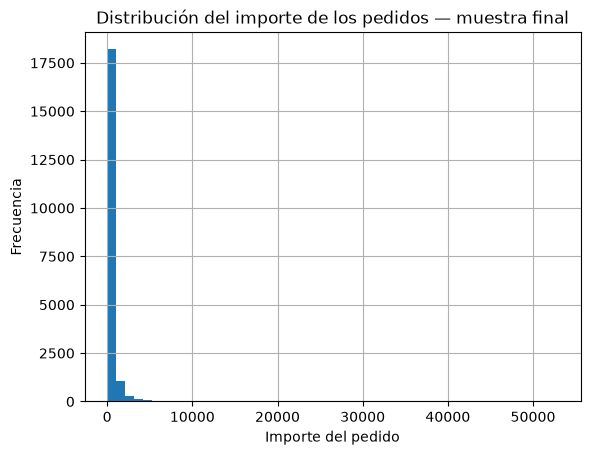

In [28]:
orders_final["OrderAmount"].hist(bins=50)

plt.title("Distribución del importe de los pedidos — muestra final")
plt.xlabel("Importe del pedido")
plt.ylabel("Frecuencia")
plt.show()

#### Distribución del importe en la muestra final

Tras excluir los pedidos identificados como completamente revertidos, la distribución del importe continúa presentando una marcada asimetría positiva.

Aunque los valores extremos se reducen considerablemente, la mayor parte de los pedidos sigue concentrándose en importes relativamente bajos, mientras que existe una cola derecha formada por pedidos de mayor valor.

Por tanto, la asimetría observada no puede atribuirse únicamente a operaciones anuladas, sino que constituye una característica de la distribución de los pedidos incluidos en la muestra final.

Esta estructura debe tenerse en cuenta antes de estimar un modelo de regresión lineal, ya que las observaciones de gran importe pueden ejercer una influencia elevada sobre la estimación mediante mínimos cuadrados ordinarios.

In [29]:
import numpy as np

In [30]:
orders_final["LogOrderAmount"] = np.log(
    orders_final["OrderAmount"]
)

orders_final[
    ["OrderAmount", "LogOrderAmount"]
].describe()

,OrderAmount,LogOrderAmount
count,19879.000000,19879.000000
mean,520.378033,5.557377
std,1210.346877,1.229515
min,0.380000,-0.967584
25%,151.900000,5.023222
50%,303.300000,5.714722
75%,492.940000,6.200387
max,52940.940000,10.876932


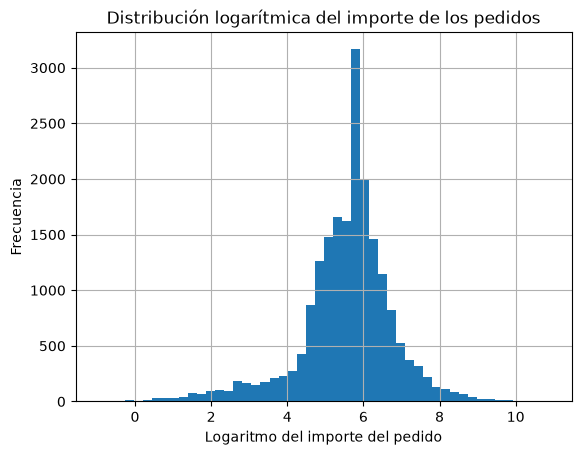

In [31]:
orders_final["LogOrderAmount"].hist(bins=50)

plt.title("Distribución logarítmica del importe de los pedidos")
plt.xlabel("Logaritmo del importe del pedido")
plt.ylabel("Frecuencia")
plt.show()

#### Efecto de la transformación logarítmica

La transformación logarítmica modifica considerablemente la forma de la distribución del importe de los pedidos.

En comparación con la variable original, la concentración de observaciones en valores bajos y la extensa cola derecha se reducen de forma notable. La distribución de `LogOrderAmount` presenta una forma mucho más equilibrada, aunque no perfectamente normal.

La transformación permite limitar la influencia relativa de los pedidos de importe excepcionalmente elevado sin necesidad de eliminarlos de la muestra.

Estos resultados sugieren que `LogOrderAmount` puede constituir una variable dependiente más adecuada para la regresión. No obstante, la elección definitiva se complementará posteriormente con el análisis de los residuos y los diagnósticos del modelo.

In [32]:
orders_final["LogTotalUnits"] = np.log(
    orders_final["TotalUnits"]
)

orders_final["LogUniqueProducts"] = np.log(
    orders_final["UniqueProducts"]
)

orders_final[
    [
        "LogOrderAmount",
        "LogTotalUnits",
        "LogUniqueProducts"
    ]
].describe()

,LogOrderAmount,LogTotalUnits,LogUniqueProducts
count,19879.000000,19879.000000,19879.000000
mean,5.557377,4.827038,2.554667
std,1.229515,1.406456,1.237862
min,-0.967584,0.000000,0.000000
25%,5.023222,4.248495,1.791759
50%,5.714722,5.017280,2.708050
75%,6.200387,5.688667,3.367296
max,10.876932,9.619067,7.012115


In [33]:
print("CORRELACIONES — VARIABLES ORIGINALES")

display(
    orders_final[
        ["OrderAmount", "TotalUnits", "UniqueProducts"]
    ].corr()
)

print("\nCORRELACIONES — VARIABLES LOGARÍTMICAS")

display(
    orders_final[
        ["LogOrderAmount", "LogTotalUnits", "LogUniqueProducts"]
    ].corr()
)

CORRELACIONES — VARIABLES ORIGINALES


,OrderAmount,TotalUnits,UniqueProducts
OrderAmount,1.000000,0.796671,0.396612
TotalUnits,0.796671,1.000000,0.268246
UniqueProducts,0.396612,0.268246,1.000000



CORRELACIONES — VARIABLES LOGARÍTMICAS


,LogOrderAmount,LogTotalUnits,LogUniqueProducts
LogOrderAmount,1.000000,0.860706,0.613873
LogTotalUnits,0.860706,1.000000,0.615813
LogUniqueProducts,0.613873,0.615813,1.000000


### Relaciones entre las variables cuantitativas

El análisis de correlación muestra asociaciones positivas entre el importe del pedido, el número de unidades adquiridas y la variedad de productos incluidos.

En las variables originales, `OrderAmount` presenta una correlación elevada con `TotalUnits` (r = 0,797) y una correlación moderada con `UniqueProducts` (r = 0,397).

Tras aplicar las transformaciones logarítmicas, las relaciones son más intensas y potencialmente más lineales. La correlación entre `LogOrderAmount` y `LogTotalUnits` alcanza 0,861, mientras que la correlación entre `LogOrderAmount` y `LogUniqueProducts` es de 0,614.

También se observa una correlación de 0,616 entre `LogTotalUnits` y `LogUniqueProducts`. Esta relación indica que ambas variables explicativas comparten parte de la información, aunque la existencia de multicolinealidad deberá evaluarse posteriormente mediante el factor de inflación de la varianza (VIF).

Estas correlaciones representan asociaciones estadísticas y no deben interpretarse como relaciones causales.

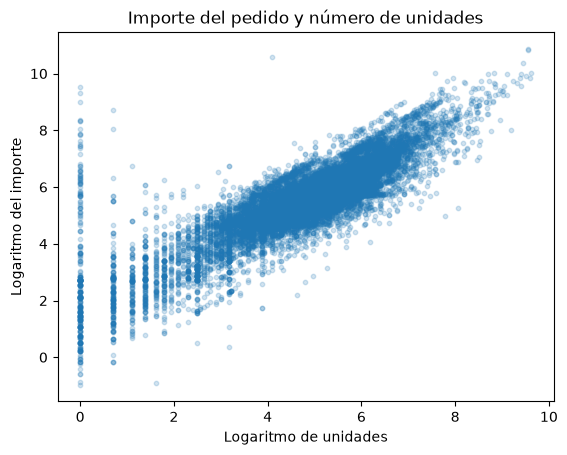

In [34]:
plt.scatter(
    orders_final["LogTotalUnits"],
    orders_final["LogOrderAmount"],
    alpha=0.2,
    s=10
)

plt.title("Importe del pedido y número de unidades")
plt.xlabel("Logaritmo de unidades")
plt.ylabel("Logaritmo del importe")
plt.show()

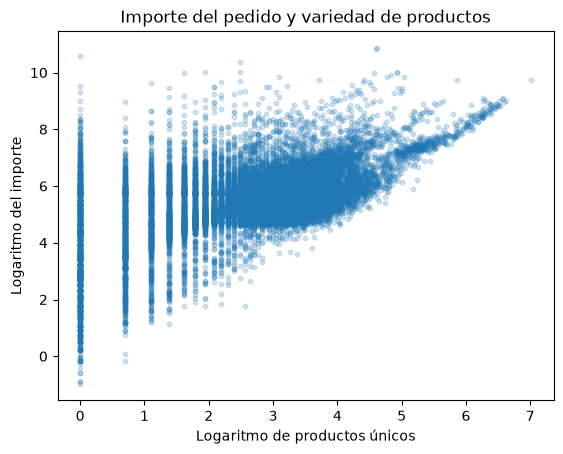

In [35]:
plt.scatter(
    orders_final["LogUniqueProducts"],
    orders_final["LogOrderAmount"],
    alpha=0.2,
    s=10
)

plt.title("Importe del pedido y variedad de productos")
plt.xlabel("Logaritmo de productos únicos")
plt.ylabel("Logaritmo del importe")
plt.show()

### Análisis gráfico de las relaciones

Los diagramas de dispersión muestran una asociación positiva entre las características de los pedidos y su importe.

La relación entre `LogTotalUnits` y `LogOrderAmount` presenta un patrón positivo y aproximadamente lineal. Los pedidos con un mayor número de unidades tienden a presentar también un mayor importe económico. Este resultado es coherente con la elevada correlación observada entre ambas variables (r = 0,861).

La relación entre `LogUniqueProducts` y `LogOrderAmount` también es positiva, aunque presenta una mayor dispersión. Esto indica que una mayor variedad de productos está asociada con pedidos de mayor importe, pero la relación es menos intensa que la observada con el número total de unidades.

Las bandas verticales visibles en ambos gráficos se deben al carácter discreto de las variables originales `TotalUnits` y `UniqueProducts`, que toman valores enteros antes de aplicar la transformación logarítmica.

Los resultados respaldan la inclusión de ambas variables como posibles predictores del importe del pedido. Su contribución conjunta y la posible multicolinealidad entre ellas se evaluarán mediante un modelo de regresión múltiple.

## 5. Preparación de variables para la regresión

Además de las características económicas y de composición del pedido, se incorporan variables temporales derivadas de la fecha y hora de la transacción.

Se obtienen el mes, el día de la semana y la hora del pedido. Estas variables permitirán analizar si, una vez controladas otras características del pedido, existen diferencias sistemáticas en su importe asociadas al momento en que se realiza la compra.

Estas variables se utilizarán como características temporales y su interpretación se realizará en términos de asociación, no de causalidad.

In [36]:
orders_final["Month"] = orders_final["InvoiceDate"].dt.month
orders_final["DayOfWeek"] = orders_final["InvoiceDate"].dt.dayofweek
orders_final["Hour"] = orders_final["InvoiceDate"].dt.hour

orders_final[
    [
        "InvoiceDate",
        "Month",
        "DayOfWeek",
        "Hour"
    ]
].head()

,InvoiceDate,Month,DayOfWeek,Hour
0,2010-12-01 08:26:00,12,2,8
1,2010-12-01 08:28:00,12,2,8
2,2010-12-01 08:34:00,12,2,8
3,2010-12-01 08:34:00,12,2,8
4,2010-12-01 08:35:00,12,2,8


### Análisis descriptivo de las variables temporales

Antes de incorporar las variables temporales al modelo de regresión, se analiza su relación descriptiva con el importe de los pedidos.

El objetivo es comprobar si existen diferencias en el importe medio y mediano según el mes, el día de la semana y la hora de realización del pedido.

Estas comparaciones son descriptivas y no implican que el momento de realización del pedido sea la causa de las diferencias observadas.

In [37]:
day_names = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

orders_final["DayName"] = (
    orders_final["DayOfWeek"]
    .map(day_names)
)

day_summary = (
    orders_final
    .groupby(["DayOfWeek", "DayName"])
    .agg(
        Orders=("Invoice", "count"),
        MeanAmount=("OrderAmount", "mean"),
        MedianAmount=("OrderAmount", "median")
    )
    .reset_index()
    .sort_values("DayOfWeek")
)

day_summary

,DayOfWeek,DayName,Orders,MeanAmount,MedianAmount
0,0,Lunes,3099,566.363543,306.02
1,1,Martes,3541,590.850243,310.78
2,2,Miércoles,3678,500.651446,304.46
3,3,Jueves,4231,516.000173,301.93
4,4,Viernes,3133,532.160367,306.03
5,6,Domingo,2197,366.582800,262.88


#### Importe de los pedidos según el día de la semana

La actividad comercial no se distribuye de manera uniforme a lo largo de la semana. No se registran pedidos los sábados, mientras que el jueves presenta el mayor número de operaciones.

El martes presenta el mayor importe medio por pedido (590,85), mientras que el domingo registra el menor (366,58). Las diferencias entre las medianas de lunes a viernes son considerablemente menores, situándose aproximadamente entre 302 y 311.

El domingo también presenta una mediana inferior (262,88), lo que sugiere que los pedidos realizados ese día tienden a presentar importes menores.

La mayor variabilidad observada en las medias respecto de las medianas es consistente con la presencia de pedidos de elevado importe en determinados días.

Estas diferencias son descriptivas y no permiten establecer una relación causal entre el día de la semana y el importe del pedido.

In [38]:
hour_summary = (
    orders_final
    .groupby("Hour")
    .agg(
        Orders=("Invoice", "count"),
        MeanAmount=("OrderAmount", "mean"),
        MedianAmount=("OrderAmount", "median")
    )
    .reset_index()
)

hour_summary

,Hour,Orders,MeanAmount,MedianAmount
0,6,1,4.250000,4.250
1,7,29,1071.007241,394.440
2,8,564,502.558670,311.200
3,9,1478,550.954121,325.645
4,10,2347,578.463567,325.440
5,11,2386,514.951995,299.810
6,12,3215,446.978289,301.630
7,13,2744,456.434614,298.520
8,14,2444,478.679714,297.905
9,15,2327,579.554852,302.400


#### Importe de los pedidos según la hora

La distribución horaria muestra que la actividad comercial se concentra principalmente durante las horas centrales del día, especialmente entre las 10:00 y las 16:00. La franja de las 12:00 presenta el mayor número de pedidos, con 3.215 operaciones.

Algunas horas situadas en los extremos de la jornada presentan importes medios elevados, pero cuentan con un número muy reducido de observaciones. Por ejemplo, las 7:00 y las 20:00 presentan únicamente 29 y 18 pedidos, respectivamente. Por tanto, sus medias deben interpretarse con cautela.

En las horas con mayor volumen de operaciones, las medianas del importe son considerablemente más estables que las medias, lo que vuelve a reflejar la influencia de pedidos de elevado importe sobre la media.

Estos resultados sugieren la existencia de diferencias horarias en la actividad comercial, aunque no permiten por sí solos establecer que la hora del pedido explique dichas diferencias.

In [39]:
month_summary = (
    orders_final
    .groupby("Month")
    .agg(
        Orders=("Invoice", "count"),
        MeanAmount=("OrderAmount", "mean"),
        MedianAmount=("OrderAmount", "median")
    )
    .reset_index()
)

month_summary

,Month,Orders,MeanAmount,MedianAmount
0,1,1082,564.725647,305.87
1,2,1098,475.774918,304.25
2,3,1449,492.370863,298.00
3,4,1237,427.380373,301.80
4,5,1671,457.803543,305.45
5,6,1526,497.610216,293.48
6,7,1469,487.527101,303.29
7,8,1359,554.409684,305.63
8,9,1834,575.872624,326.26
9,10,2024,561.283360,313.29


#### Importe de los pedidos según el mes

El número de pedidos presenta variaciones a lo largo del año y aumenta especialmente durante los últimos meses. Noviembre registra el mayor volumen de actividad, con 2.759 pedidos, seguido de diciembre y octubre.

Las medianas del importe muestran una mayor estabilidad que las medias. Septiembre presenta la mediana más elevada (326,26), mientras que en la mayoría de los meses el pedido mediano se sitúa aproximadamente entre 293 y 313.

La categoría correspondiente a diciembre debe interpretarse con cautela. El periodo analizado comienza en diciembre de 2010 y finaliza el 9 de diciembre de 2011, por lo que esta categoría combina observaciones de diciembre de dos años y no representa un único mes completo comparable directamente con el resto.

En conjunto, las diferencias mensuales parecen afectar de forma más evidente al volumen de pedidos que al importe típico de cada operación.

In [40]:
country_summary = (
    orders_final
    .groupby("Country")
    .agg(
        Orders=("Invoice", "count"),
        MeanAmount=("OrderAmount", "mean"),
        MedianAmount=("OrderAmount", "median")
    )
    .sort_values("Orders", ascending=False)
)

country_summary.head(15)

,Orders,MeanAmount,MedianAmount
Country,,,
United Kingdom,17959,485.712224,299.950
Germany,453,501.129470,354.850
France,389,534.009280,374.680
EIRE,286,974.788881,651.725
Belgium,98,420.370816,346.390
Netherlands,94,3036.663191,806.880
Spain,90,683.984000,431.890
Australia,54,2558.374259,446.900
Switzerland,54,1056.807407,625.965


### Distribución geográfica de los pedidos

La muestra presenta una fuerte concentración geográfica en el Reino Unido, que representa aproximadamente el 90 % de los pedidos analizados.

Los principales mercados internacionales son Alemania, Francia e Irlanda, aunque su número de pedidos es considerablemente inferior al del mercado británico. En algunos países, como Países Bajos o Australia, el importe medio es muy elevado en comparación con la mediana, lo que indica la presencia de pedidos internacionales de gran volumen.

Debido al reducido número de observaciones de numerosos países, incorporar una variable categórica independiente para cada uno generaría múltiples grupos con escasa representación.

Por este motivo, para la regresión se simplifica la dimensión geográfica distinguiendo entre pedidos realizados en el Reino Unido y pedidos internacionales.

In [41]:
orders_final["International"] = (
    orders_final["Country"] != "United Kingdom"
).astype(int)

international_summary = (
    orders_final
    .groupby("International")
    .agg(
        Orders=("Invoice", "count"),
        MeanAmount=("OrderAmount", "mean"),
        MedianAmount=("OrderAmount", "median")
    )
)

international_summary

,Orders,MeanAmount,MedianAmount
International,,,
0,17959,485.712224,299.95
1,1920,844.629734,424.43


#### Mercado nacional e internacional

La agrupación geográfica muestra que 17.959 pedidos corresponden al Reino Unido y 1.920 a mercados internacionales.

Los pedidos internacionales presentan un importe medio de 844,63 y una mediana de 424,43, superiores a los valores observados en el Reino Unido, donde la media es de 485,71 y la mediana de 299,95.

La diferencia observada tanto en la media como en la mediana sugiere que los pedidos internacionales tienden a presentar un mayor importe. No obstante, esta comparación es únicamente descriptiva, ya que ambos grupos pueden diferir también en otras características, como el número de unidades o la variedad de productos adquiridos.

La variable `International` se incorpora posteriormente al modelo de regresión como variable dummy, tomando el valor 0 para los pedidos del Reino Unido y 1 para los pedidos internacionales.

## 6. Regresión lineal múltiple

El objetivo del modelo de regresión es analizar la asociación entre las características de los pedidos y su importe económico, controlando simultáneamente por diferentes factores.

Como variable dependiente se utiliza `LogOrderAmount`, dado que la transformación logarítmica reduce considerablemente la asimetría observada en el importe original.

El modelo inicial incluye como variables explicativas:

- `LogTotalUnits`: logaritmo del número total de unidades del pedido.
- `LogUniqueProducts`: logaritmo del número de productos diferentes.
- `International`: variable dummy que toma el valor 1 para pedidos internacionales y 0 para pedidos del Reino Unido.

Este primer modelo permite estimar la asociación de cada característica con el importe del pedido manteniendo constantes las restantes variables incluidas.

In [42]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import statsmodels.api as sm

print(sm.__version__)

0.15.0


In [44]:
X = orders_final[
    [
        "LogTotalUnits",
        "LogUniqueProducts",
        "International"
    ]
]

y = orders_final["LogOrderAmount"]

# Añadimos la constante del modelo
X = sm.add_constant(X)

# Estimación mediante mínimos cuadrados ordinarios (OLS)
model_1 = sm.OLS(y, X).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:         LogOrderAmount   R-squared:                       0.755
Model:                            OLS   Adj. R-squared:                  0.755
Method:                 Least Squares   F-statistic:                 2.043e+04
Date:                Sun, 06 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:02:29   Log-Likelihood:                -18328.
No. Observations:               19879   AIC:                         3.666e+04
Df Residuals:                   19875   BIC:                         3.670e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 1.9321      0.01

### Resultados del modelo inicial

El modelo de regresión presenta un coeficiente de determinación R² de 0,755, lo que indica que las variables incluidas explican aproximadamente el 75,5 % de la variabilidad observada en el logaritmo del importe de los pedidos. El modelo es globalmente significativo (p < 0,001).

Las tres variables explicativas presentan coeficientes positivos y estadísticamente significativos (p < 0,001).

El coeficiente de `LogTotalUnits` es 0,674. Al tratarse de una relación log-log, este resultado indica que, manteniendo constantes las demás variables, un aumento del 1 % en el número de unidades está asociado aproximadamente con un aumento del 0,674 % en el importe del pedido.

El coeficiente de `LogUniqueProducts` es 0,136. Por tanto, manteniendo constantes las demás características incluidas en el modelo, un aumento del 1 % en el número de productos diferentes está asociado aproximadamente con un incremento del 0,136 % en el importe del pedido.

La variable `International` presenta un coeficiente de 0,229. Al tratarse de una variable dummy con una variable dependiente expresada en logaritmos, su efecto se interpreta mediante la transformación exp(β) − 1. El resultado indica que los pedidos internacionales presentan un importe estimado aproximadamente un 25,8 % superior al de los pedidos del Reino Unido, manteniendo constantes el número de unidades y la variedad de productos.

Los resultados representan asociaciones estadísticas y no deben interpretarse como efectos causales.

### Diagnóstico de multicolinealidad

Antes de ampliar el modelo se evalúa la posible existencia de multicolinealidad entre las variables explicativas.

Para ello se utiliza el factor de inflación de la varianza (VIF), que permite cuantificar hasta qué punto la varianza estimada de cada coeficiente aumenta debido a su relación lineal con las restantes variables explicativas.

In [45]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()
vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

vif

,Variable,VIF
0,const,1.000000
1,LogTotalUnits,1.623686
2,LogUniqueProducts,1.612503
3,International,1.008813


#### Resultado del análisis de multicolinealidad

Los factores de inflación de la varianza (VIF) obtenidos son bajos para todas las variables explicativas.

`LogTotalUnits` presenta un VIF de 1,624 y `LogUniqueProducts` de 1,613, mientras que `International` presenta un valor próximo a 1.

Estos resultados indican que, aunque existe cierta correlación entre el número de unidades y la variedad de productos del pedido, esta relación no genera un problema relevante de multicolinealidad en el modelo.

Por tanto, las tres variables pueden mantenerse conjuntamente en la especificación de la regresión.

### Incorporación de controles temporales

A partir del modelo inicial se estima una segunda especificación que incorpora controles temporales correspondientes al día de la semana y al mes del pedido.

Estas variables se introducen como variables categóricas, evitando asumir que la diferencia entre dos días o meses consecutivos tiene un efecto lineal constante.

El objetivo es comprobar si las asociaciones observadas para las principales características del pedido se mantienen una vez consideradas posibles diferencias temporales en la actividad comercial.

In [46]:
import statsmodels.formula.api as smf

model_2 = smf.ols(
    formula=(
        "LogOrderAmount ~ LogTotalUnits + LogUniqueProducts "
        "+ International + C(DayOfWeek) + C(Month)"
    ),
    data=orders_final
).fit()

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:         LogOrderAmount   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     3252.
Date:                Sun, 06 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:02:29   Log-Likelihood:                -18263.
No. Observations:               19879   AIC:                         3.657e+04
Df Residuals:                   19859   BIC:                         3.672e+04
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             1.9969      0.02

#### Comparación entre el modelo inicial y el modelo con controles temporales

La incorporación de controles por día de la semana y mes produce cambios mínimos en los coeficientes de las principales variables explicativas.

El coeficiente de `LogTotalUnits` pasa de 0,6743 en el modelo inicial a 0,6738 en el modelo con controles temporales. De forma similar, el coeficiente de `LogUniqueProducts` cambia de 0,1363 a 0,1388 y el de `International` de 0,2294 a 0,2270.

La elevada estabilidad de estos coeficientes indica que las asociaciones observadas entre las características del pedido y su importe se mantienen prácticamente inalteradas tras controlar por diferencias temporales.

Además, el R² ajustado aumenta únicamente de 0,755 a 0,757, por lo que la incorporación del mes y del día de la semana aporta una mejora limitada en la capacidad explicativa del modelo.

En conjunto, los resultados sugieren que el número de unidades, la variedad de productos y el carácter internacional del pedido concentran la mayor parte de la capacidad explicativa de las variables analizadas, mientras que los controles temporales aportan información adicional relativamente reducida.

In [47]:
comparison = pd.DataFrame({
    "Modelo 1": model_1.params[
        ["LogTotalUnits", "LogUniqueProducts", "International"]
    ],
    "Modelo 2": model_2.params[
        ["LogTotalUnits", "LogUniqueProducts", "International"]
    ]
})

comparison

,Modelo 1,Modelo 2
LogTotalUnits,0.674293,0.673772
LogUniqueProducts,0.136332,0.138843
International,0.229354,0.226954


In [48]:
print(f"Modelo 1 - R² ajustado: {model_1.rsquared_adj:.4f}")
print(f"Modelo 2 - R² ajustado: {model_2.rsquared_adj:.4f}")

Modelo 1 - R² ajustado: 0.7551
Modelo 2 - R² ajustado: 0.7565


#### Comparación entre el modelo inicial y el modelo con controles temporales

La incorporación de controles por día de la semana y mes produce cambios mínimos en los coeficientes de las principales variables explicativas.

El coeficiente de `LogTotalUnits` pasa de 0,6743 en el modelo inicial a 0,6738 en el modelo con controles temporales. De forma similar, el coeficiente de `LogUniqueProducts` cambia de 0,1363 a 0,1388 y el de `International` de 0,2294 a 0,2270.

La elevada estabilidad de estos coeficientes indica que las asociaciones observadas entre las características del pedido y su importe se mantienen prácticamente inalteradas tras controlar por diferencias temporales.

El R² ajustado aumenta de 0,7551 a 0,7565. Esta mejora es reducida, lo que indica que la incorporación del mes y del día de la semana aporta una capacidad explicativa adicional limitada.

En conjunto, los resultados sugieren que el número de unidades, la variedad de productos y el carácter internacional del pedido concentran la mayor parte de la capacidad explicativa de las variables analizadas, mientras que los controles temporales aportan información adicional relativamente reducida.

## 7. Diagnóstico del modelo

Una vez estimado el modelo de regresión múltiple, se analizan sus residuos para evaluar si se cumplen adecuadamente los principales supuestos del modelo lineal.

En particular, se estudia la relación entre los valores ajustados y los residuos para detectar posibles patrones sistemáticos y cambios en su dispersión.

También se evaluará formalmente la posible presencia de heterocedasticidad. En caso de detectarse, se utilizarán errores estándar robustos para obtener una inferencia estadística más adecuada.

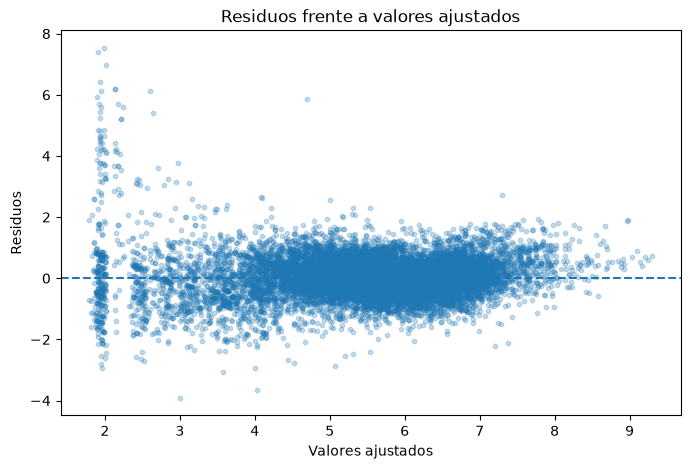

In [49]:
import matplotlib.pyplot as plt

fitted_values = model_2.fittedvalues
residuals = model_2.resid

plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.25, s=10)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos frente a valores ajustados")
plt.show()

### Análisis gráfico de los residuos

El gráfico de residuos frente a valores ajustados muestra que los residuos se distribuyen alrededor de cero, aunque su dispersión no permanece constante a lo largo de todo el rango de valores predichos.

En particular, para los valores ajustados más bajos se observa una mayor variabilidad de los residuos y algunas observaciones con desviaciones especialmente elevadas. En las zonas centrales de la distribución, la dispersión es considerablemente menor.

Este patrón proporciona evidencia visual compatible con la presencia de heterocedasticidad, es decir, una varianza de los errores que puede variar en función del nivel de los valores ajustados.

La evidencia gráfica se complementará con un contraste formal de heterocedasticidad antes de decidir si es necesario utilizar errores estándar robustos.

In [50]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model_2.resid,
    model_2.model.exog
)

bp_results = pd.Series(
    bp_test,
    index=[
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ]
)

bp_results

LM Statistic     1.322412e+03
LM p-value      5.541818e-269
F Statistic      7.448564e+01
F p-value       1.104223e-278
dtype: float64

### Contraste de heterocedasticidad

Para evaluar formalmente si la varianza de los errores permanece constante se aplica el contraste de Breusch-Pagan.

La hipótesis nula del contraste establece que los errores son homocedásticos. Los resultados muestran valores p extremadamente reducidos tanto para el estadístico LM como para el estadístico F (p < 0,001).

Por tanto, se rechaza la hipótesis nula de homocedasticidad y se concluye que existe evidencia estadística de heterocedasticidad.

Este resultado es coherente con el patrón observado previamente en el gráfico de residuos. En consecuencia, los errores estándar convencionales del modelo OLS pueden no ser adecuados para realizar inferencia estadística.

Para corregir este problema se estimarán errores estándar robustos a heterocedasticidad mediante el método HC3.

In [51]:
model_2_hc3 = model_2.get_robustcov_results(cov_type="HC3")

print(model_2_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:         LogOrderAmount   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     1125.
Date:                Sun, 06 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:02:29   Log-Likelihood:                -18263.
No. Observations:               19879   AIC:                         3.657e+04
Df Residuals:                   19859   BIC:                         3.672e+04
Df Model:                          19                                         
Covariance Type:                  HC3                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             1.9969      0.03

### Estimación con errores estándar robustos HC3

Dado que el contraste de Breusch-Pagan confirma la presencia de heterocedasticidad, se recalculan los errores estándar del modelo mediante el estimador robusto HC3.

Esta corrección no modifica los coeficientes estimados por mínimos cuadrados ordinarios ni el R² del modelo. Su objetivo es obtener errores estándar, estadísticos t, valores p e intervalos de confianza robustos frente a la presencia de heterocedasticidad.

De esta forma, se mantiene la especificación del modelo de regresión, pero se mejora la fiabilidad de la inferencia estadística asociada a sus coeficientes.

A continuación, se comparan los errores estándar y los valores p obtenidos mediante la estimación convencional con los correspondientes a la corrección robusta HC3.

In [52]:
variables_principales = [
    "LogTotalUnits",
    "LogUniqueProducts",
    "International"
]

hc3_results = pd.DataFrame({
    "Coeficiente": model_2.params[variables_principales],
    "SE convencional": model_2.bse[variables_principales],
    "p convencional": model_2.pvalues[variables_principales],
    "SE HC3": pd.Series(
        model_2_hc3.bse,
        index=model_2.params.index
    )[variables_principales],
    "p HC3": pd.Series(
        model_2_hc3.pvalues,
        index=model_2.params.index
    )[variables_principales]
})

hc3_results

,Coeficiente,SE convencional,p convencional,SE HC3,p HC3
LogTotalUnits,0.673772,0.003919,0.000000e+00,0.006951,0.000000e+00
LogUniqueProducts,0.138843,0.004448,7.098460e-209,0.005202,3.368146e-154
International,0.226954,0.014660,9.505443e-54,0.017106,5.274384e-40


#### Resultados con errores estándar robustos

La aplicación de errores estándar robustos HC3 incrementa la incertidumbre estimada de los coeficientes respecto al modelo convencional, confirmando la importancia de corregir la heterocedasticidad detectada previamente.

El cambio es especialmente visible en `LogTotalUnits`, cuyo error estándar aumenta de 0,0039 a 0,0070. En `LogUniqueProducts` aumenta de 0,0044 a 0,0052 y en `International` de 0,0147 a 0,0171.

A pesar de este ajuste, las tres variables principales continúan siendo estadísticamente significativas (p < 0,001). Por tanto, las conclusiones fundamentales del modelo se mantienen después de utilizar una inferencia robusta frente a heterocedasticidad.

Los coeficientes estimados permanecen inalterados: 0,674 para `LogTotalUnits`, 0,139 para `LogUniqueProducts` y 0,227 para `International`.

### Distribución de los residuos

Como parte del diagnóstico del modelo se analiza también la distribución de los residuos mediante un gráfico Q-Q.

Este gráfico compara los cuantiles observados de los residuos con los cuantiles que se esperarían bajo una distribución normal.

Si los residuos siguieran aproximadamente una distribución normal, los puntos deberían situarse cerca de la línea de referencia. Las desviaciones sistemáticas, especialmente en los extremos, permiten identificar asimetrías o colas más pronunciadas que las esperadas bajo normalidad.

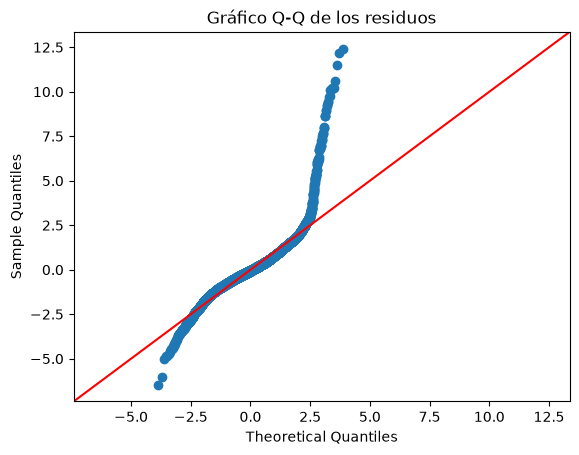

In [53]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

sm.qqplot(
    model_2.resid,
    line="45",
    fit=True
)

plt.title("Gráfico Q-Q de los residuos")
plt.show()

#### Normalidad de los residuos

El gráfico Q-Q muestra que los residuos se aproximan a la distribución normal en la zona central, pero presentan desviaciones importantes en ambas colas, especialmente en la cola superior.

Por tanto, la distribución de los residuos no puede considerarse estrictamente normal y presenta colas más pronunciadas que las esperadas bajo normalidad. Este resultado es coherente con los estadísticos de normalidad obtenidos previamente en la estimación del modelo.

La desviación de la normalidad debe tenerse en cuenta como una limitación del modelo. No obstante, el análisis se basa en una muestra amplia de 19.879 pedidos y la inferencia estadística se realiza utilizando errores estándar robustos HC3 debido a la heterocedasticidad previamente detectada.

En consecuencia, los resultados del modelo se interpretan considerando estas limitaciones y evitando atribuirles un carácter causal.

## 8. Resultados finales del modelo

Una vez realizado el diagnóstico, se utiliza como especificación final el modelo que incorpora las principales características del pedido y los controles temporales por mes y día de la semana.

Debido a la presencia de heterocedasticidad, la inferencia estadística se basa en errores estándar robustos HC3.

A continuación se presentan los resultados correspondientes a las principales variables explicativas del modelo.

In [54]:
import numpy as np

param_names = model_2.params.index

hc3_params = pd.Series(model_2_hc3.params, index=param_names)
hc3_bse = pd.Series(model_2_hc3.bse, index=param_names)
hc3_pvalues = pd.Series(model_2_hc3.pvalues, index=param_names)

hc3_ci = pd.DataFrame(
    model_2_hc3.conf_int(),
    index=param_names,
    columns=["IC 95% inferior", "IC 95% superior"]
)

final_results = pd.DataFrame({
    "Coeficiente": hc3_params[variables_principales],
    "Error estándar HC3": hc3_bse[variables_principales],
    "p-valor": hc3_pvalues[variables_principales],
    "IC 95% inferior": hc3_ci.loc[variables_principales, "IC 95% inferior"],
    "IC 95% superior": hc3_ci.loc[variables_principales, "IC 95% superior"]
})

final_results.round(4)

,Coeficiente,Error estándar HC3,p-valor,IC 95% inferior,IC 95% superior
LogTotalUnits,0.6738,0.0070,0.0,0.6601,0.6874
LogUniqueProducts,0.1388,0.0052,0.0,0.1286,0.1490
International,0.2270,0.0171,0.0,0.1934,0.2605


### Interpretación del modelo final

Los resultados del modelo final muestran que las tres características principales analizadas mantienen una asociación positiva y estadísticamente significativa con el importe del pedido después de incorporar controles temporales y utilizar errores estándar robustos HC3 (p < 0,001).

El coeficiente de `LogTotalUnits` es 0,674 (IC 95 %: 0,660–0,687). Al tratarse de una especificación log-log, un aumento del 1 % en el número total de unidades está asociado aproximadamente con un incremento del 0,674 % en el importe del pedido, manteniendo constantes las demás variables incluidas en el modelo.

El coeficiente de `LogUniqueProducts` es 0,139 (IC 95 %: 0,129–0,149). Por tanto, manteniendo constantes las demás variables, un aumento del 1 % en el número de productos diferentes está asociado aproximadamente con un incremento del 0,139 % en el importe del pedido.

La variable `International` presenta un coeficiente de 0,227 (IC 95 %: 0,193–0,261). Al transformar este coeficiente mediante `exp(β) − 1`, se estima que los pedidos internacionales presentan un importe aproximadamente un 25,5 % superior al de los pedidos realizados en el Reino Unido, manteniendo constantes las restantes características incluidas en el modelo.

Entre las variables analizadas, el número total de unidades presenta la asociación más intensa con el importe del pedido. La variedad de productos aporta una asociación positiva adicional, mientras que el carácter internacional del pedido también se relaciona con un mayor importe esperado.

El modelo presenta un R² ajustado de 0,7565, por lo que explica aproximadamente el 75,7 % de la variabilidad observada en el logaritmo del importe de los pedidos. Los resultados describen asociaciones estadísticas y no deben interpretarse como relaciones causales.

## 9. Limitaciones del análisis

Los resultados deben interpretarse teniendo en cuenta varias limitaciones.

En primer lugar, el análisis utiliza datos observacionales, por lo que las asociaciones estimadas mediante regresión no permiten establecer relaciones causales.

Además, existe una relación estructural entre el número de unidades y el importe del pedido, ya que el valor económico de una compra depende necesariamente de las cantidades adquiridas y de los precios de los productos. Por este motivo, la elevada asociación observada entre `TotalUnits` y `OrderAmount` debe interpretarse principalmente como una relación descriptiva y predictiva.

El tratamiento de las cancelaciones se basa en un procedimiento de emparejamiento entre ventas y operaciones posteriores de signo contrario. Aunque este método permite identificar pedidos con evidencia de reversión completa, no garantiza la identificación de todas las posibles devoluciones o cancelaciones del conjunto de datos.

La muestra presenta además una fuerte concentración de pedidos en el Reino Unido, mientras que los mercados internacionales contienen un número considerablemente menor de observaciones. Por ello, la variable `International` resume mercados con características heterogéneas.

El periodo disponible comprende aproximadamente un año y diciembre aparece representado de forma particular, ya que el dataset comienza en diciembre de 2010 y finaliza el 9 de diciembre de 2011.

Finalmente, el diagnóstico detectó heterocedasticidad y desviaciones de la normalidad en los residuos. Para reducir el impacto de la heterocedasticidad sobre la inferencia estadística se utilizaron errores estándar robustos HC3.

## 10. Conclusiones

El objetivo del análisis fue estudiar qué características de los pedidos están asociadas con un mayor importe de compra en el dataset Online Retail II.

Los resultados muestran que el número total de unidades constituye la variable con mayor asociación con el importe del pedido. Manteniendo constantes las demás características analizadas, un aumento del 1 % en el número de unidades está asociado aproximadamente con un incremento del 0,674 % en el importe.

La variedad de productos también presenta una asociación positiva. Un aumento del 1 % en el número de productos diferentes está asociado aproximadamente con un incremento del 0,139 % en el importe del pedido, manteniendo constantes las restantes variables.

Asimismo, los pedidos internacionales presentan un importe estimado aproximadamente un 25,5 % superior al de los pedidos realizados en el Reino Unido, una vez controlados el volumen, la variedad de productos y las diferencias temporales incluidas en el modelo.

La incorporación de controles por mes y día de la semana apenas modifica los coeficientes principales y produce una mejora reducida del R² ajustado, que pasa de 0,7551 a 0,7565. Esto indica que las principales asociaciones identificadas son estables frente a la incorporación de estos controles.

El diagnóstico del modelo detectó heterocedasticidad, por lo que la inferencia final se realizó utilizando errores estándar robustos HC3. Las tres variables principales permanecen estadísticamente significativas bajo esta corrección.

En conjunto, el modelo final explica aproximadamente el 75,7 % de la variabilidad del logaritmo del importe de los pedidos. Los resultados permiten identificar patrones relevantes en el comportamiento económico de las compras, aunque deben interpretarse como asociaciones estadísticas y no como relaciones causales.

In [55]:
pip freeze

asttokens==3.0.2
colorama==0.4.6
comm==0.2.3
contourpy==1.3.3
cycler==0.12.1
debugpy==1.8.21
et_xmlfile==2.0.0
executing==2.2.1
fonttools==4.63.0
formulaic==1.2.2
interface_meta==2.0.1
ipykernel==7.3.0
ipython==9.16.1
ipython_pygments_lexers==1.1.1
jedi==0.20.0
joblib==1.5.3
jupyter_client==8.9.1
jupyter_core==5.9.1
kiwisolver==1.5.0
matplotlib==3.11.0
matplotlib-inline==0.2.2
narwhals==2.22.1
nest-asyncio2==1.7.2
numpy==2.4.6
openpyxl==3.1.5
packaging==26.2
pandas==3.0.3
parso==0.8.7
patsy==1.0.3
pillow==12.2.0
platformdirs==4.11.3
prompt_toolkit==3.0.53
psutil==7.2.2
pure_eval==0.2.3
Pygments==2.20.0
pyparsing==3.3.2
python-dateutil==2.9.0.post0
pyzmq==27.1.0
scikit-learn==1.9.0
scipy==1.18.0
six==1.17.0
stack-data==0.6.3
statsmodels==0.15.0
threadpoolctl==3.6.0
tornado==6.5.8
traitlets==5.16.1
typing_extensions==4.16.0
tzdata==2026.2
wcwidth==0.8.2
wrapt==2.4.1rc1
Note: you may need to restart the kernel to use updated packages.


In [56]:
pip freeze | findstr /I "pandas numpy matplotlib statsmodels"

matplotlib==3.11.0
matplotlib-inline==0.2.2
numpy==2.4.6
pandas==3.0.3
statsmodels==0.15.0
Note: you may need to restart the kernel to use updated packages.


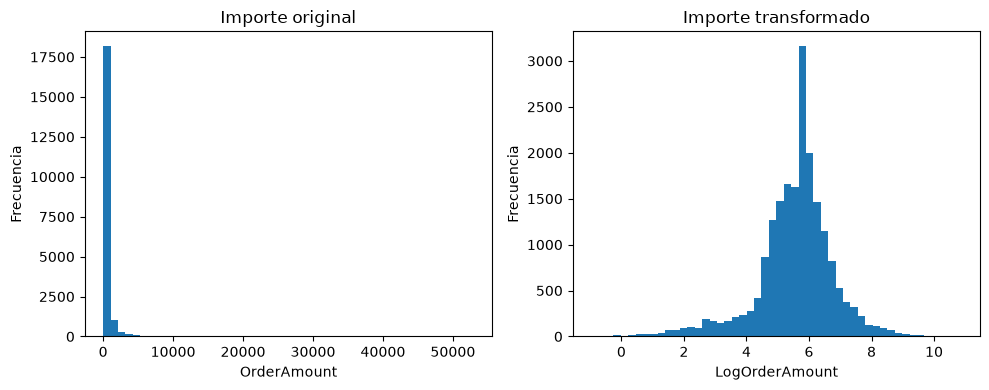

: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(orders_final["OrderAmount"], bins=50)
axes[0].set_title("Importe original")
axes[0].set_xlabel("OrderAmount")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(orders_final["LogOrderAmount"], bins=50)
axes[1].set_title("Importe transformado")
axes[1].set_xlabel("LogOrderAmount")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()